# Pjesa I · 2/4: Pastrimi final i të dhënave

**Pyetja e analizës:** si ndryshon çmimi për natë i listimeve Airbnb në Londër? Për ta analizuar, na duhet një tabelë me çmim të vlefshëm, pa dublikatë, me mungesa të shpjeguara dhe pa çmime që janë gabime të dukshme.

Ky notebook e ndërton atë tabelë nga skedari origjinal i Inside Airbnb, i cili nuk ndryshohet kurrë. Çdo hap tregon çfarë bëhet, pse bëhet dhe sa rreshta ose vlera preken.

| Hapi | Çfarë bëhet |
|---|---|
| 1. Pastrimi bazë | heqim kolonat krejt bosh, kolonat konstante (`scrape_id`) dhe ID-të e dyfishta; çmimin, datat dhe fushat `t/f` i kthejmë në tipet e duhura |
| 1.1 Integrimi: komentet | bashkojmë `reviews.csv` me `listing_id = id`: numri i komenteve dhe data e parë dhe e fundit për çdo listim; mungesat e reja që krijon bashkimi trajtohen menjëherë. Rezultati përputhet 100% me kolonat ekzistuese, ndaj shërben si kontroll |
| 1.2 Integrimi: kalendari | bashkojmë `calendar.csv` me `listing_id = id`: ditët e lira dhe disponueshmëria e fundjavës sipas ditës. Çdo listim ka kalendar, ndaj nuk krijohen mungesa; informacioni i ri është modest |
| 2. Mungesat | heqim listimet pa çmim (me arsyetim); mbajmë dhe shënojmë listimet me çmim nga mbledhja e mëparshme (`is_previous_scrape`); plotësojmë `bathrooms`, `bedrooms`, `beds` dhe fushat e tjera ku ka kuptim; të tjerat i lëmë bosh me qëllim |
| 3. Vlerat ekstreme dhe anomalitë | heqim çmimet e pabesueshme (mbi percentilin 99.9 të llojit të dhomës; asimetria e çmimit bie nga 62.7 në 8.3), shënojmë ato mbi percentilin 99, kufizojmë `maximum_nights` në 1,125, shënojmë listimet me më shumë `bedrooms` se `accommodates` dhe dokumentojmë `price_quote_*` si kolona të nxjerra nga çmimi |
| 4. Vetitë e reja | `has_reviews`, `is_superhost`, `price_band` dhe `amenity_count` |
| 5. Zgjedhja e vetive | 18 kolona të lidhura me pyetjen e analizës (tabelë analize; zgjedhja përfundimtare e vetive bëhet te notebook-u 04) |
| 6. Agregimi | çmimi median sipas llojit të dhomës dhe lagjes (standardizimi dhe kodimi 0/1 bëhen te notebook-et 03 dhe 04) |
| 7. Kontrolli dhe ruajtja | para/pas, çfarë ndodhi me çdo rresht dhe çdo mungesë, kontrolle që ndalojnë ekzekutimin nëse ka mbetur problem |

**Dalja** (dy skedarë në `dataset/`):
- `listings_clean_full.csv` · tabela e plotë e pastruar, me të gjitha kolonat;
- `listings_preprocessed.csv` · tabela me 18 kolona për analizën e çmimit.

**Si ekzekutohet:** ekzekutoni së pari notebook-un 01 për të parë problemet fillestare, pastaj këtë nga rrënja e projektit ose nga `notebooks/`. Ai gjen vetë `dataset/listings.csv.gz`, `dataset/reviews.csv.gz` dhe `dataset/calendar.csv.gz` (i njëjti snapshot, 2026-09-17); për skedarë të tjerë vendosni `PVDH_DATASET_PATH`, `PVDH_REVIEWS_PATH` dhe `PVDH_CALENDAR_PATH`. Ekzekutimi i plotë zgjat nga disa dhjetëra sekonda deri në pak minuta, sipas kompjuterit; pjesa më e madhe është leximi i kalendarit.

## 0. Burimi i të dhënave

Të dhënat vijnë nga **Inside Airbnb**, listimet e Londrës (faqja: `insideairbnb.com/get-the-data`). Një rresht i `listings` përfaqëson një listim; `id` është çelësi me të cilin bashkohen skedarët e tjerë.

| Skedari | Përmbajtja | Madhësia |
|---|---|---|
| `listings.csv.gz` | një rresht për listim | 91,954 rreshta × 90 kolona |
| `reviews.csv.gz` | një rresht për koment | 2,323,969 rreshta |
| `calendar.csv.gz` | një rresht për listim dhe ditë | 33,563,890 rreshta |

Të tre janë versioni i datës **2026-09-17** (kolona `last_scraped` ka data nga 2026-09-18 deri më 2026-09-23). Lidhjet e shkarkimit:

```
https://data.insideairbnb.com/united-kingdom/england/london/2026-09-17/data/listings.csv.gz
https://data.insideairbnb.com/united-kingdom/england/london/2026-09-17/data/reviews.csv.gz
https://data.insideairbnb.com/united-kingdom/england/london/2026-09-17/data/calendar.csv.gz
```

Skedarët ruhen te `dataset/` dhe nuk përfshihen në Git (janë shumë të mëdhenj); README tregon si shkarkohen. Skedari origjinal nuk ndryshohet kurrë. Nga komentet lexojmë vetëm `listing_id` dhe `date`: emrat dhe teksti janë të dhëna personale që analiza nuk i përdor. Kushtet e përdorimit të të dhënave gjenden te faqja e burimit.

In [1]:
import json
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path(os.environ.get("PVDH_PROJECT_ROOT", Path.cwd()))
if not (ROOT / "dataset" / "listings.csv.gz").is_file() and (ROOT.parent / "dataset" / "listings.csv.gz").is_file():
    ROOT = ROOT.parent
DATA_PATH = Path(os.environ.get("PVDH_DATASET_PATH", ROOT / "dataset" / "listings.csv.gz"))
assert DATA_PATH.is_file(), f"Mungon dataset-i: {DATA_PATH}"
raw = pd.read_csv(DATA_PATH, low_memory=False, dtype={"host_profile_id": "string"})
df = raw.copy()
log = []
removed = {}  # rreshtat e larguara dhe arsyeja
def record(step):
    log.append({"hapi": step, "rreshta": len(df), "kolona": df.shape[1], "qeliza boshe": int(df.isna().sum().sum())})
record("Fillimi")
print(f"Burimi: {DATA_PATH.name} | Fillimi: {len(df):,} rreshta × {df.shape[1]} kolona")

Burimi: listings.csv.gz | Fillimi: 91,954 rreshta × 90 kolona


## 1. Pastrimi bazë dhe tipet

Heqim kolonat 100% boshe dhe ID-të e përsëritura, por ruajmë `bathrooms`: megjithëse është bosh në këtë version, mund ta rindërtojmë nga `bathrooms_text`. Heqim edhe kolonat konstante (një vlerë e vetme, pa asnjë mungesë), si `scrape_id`, sepse nuk japin asnjë informacion; `source` mbetet, sepse ka dy gjendje (bosh dhe `previous scrape`). Kthejmë `price` në numër duke larguar formatimin (`$`, presje). Datat ruhen si `datetime`, ndërsa `t/f` bëhet `True/False` pa e ngatërruar mungesën me `False`.

In [2]:
empty_columns = [col for col in df.columns[df.isna().all()] if col != "bathrooms"]
df = df.drop(columns=empty_columns)
# Kolona konstante: një vlerë e vetme dhe asnjë mungesë; nuk japin asnjë informacion (p.sh. scrape_id).
constant_columns = {col: df[col].iloc[0] for col in df.columns if df[col].notna().all() and df[col].nunique() == 1}
df = df.drop(columns=list(constant_columns))
removed["ID e dyfishuar"] = int(df["id"].duplicated().sum())
df = df.drop_duplicates(subset="id", keep="first").copy()
df["price"] = pd.to_numeric(df["price"].astype("string").str.replace(r"[$,]", "", regex=True), errors="coerce")
for col in ["last_scraped", "calendar_last_scraped", "first_review", "last_review"]:
    if col in df:
        df[col] = pd.to_datetime(df[col], errors="coerce")
boolean_columns = ["host_is_superhost", "host_has_profile_pic", "host_identity_verified", "has_availability"]
for col in boolean_columns:
    if col in df:
        df[col] = df[col].map({"t": True, "f": False}).astype("boolean")
record("Kolona boshe, konstante, ID, tipe")
print(f"Kolona 100% boshe të hequra: {len(empty_columns)}: {', '.join(empty_columns)}")
print(f"Kolona konstante të hequra: {', '.join(f'{col} = {value}' for col, value in constant_columns.items()) or 'asnjë'}")
print(f"ID të dyfishuara të hequra: {removed['ID e dyfishuar']}")
display(df[["price", "last_scraped", "host_is_superhost"]].dtypes.to_frame("tipi i korrigjuar"))

Kolona 100% boshe të hequra: 14: neighborhood_overview, host_since, host_response_time, host_response_rate, host_acceptance_rate, host_thumbnail_url, host_neighbourhood, host_total_listings_count, host_verifications, neighbourhood, neighbourhood_group_cleansed, calendar_updated, license, instant_bookable
Kolona konstante të hequra: scrape_id = 20260917015706
ID të dyfishuara të hequra: 0


,tipi i korrigjuar
price,Float64
last_scraped,datetime64[ns]
host_is_superhost,boolean


### 1.1 Integrimi: komentet nga `reviews.csv`

Deri tani kemi përdorur vetëm `listings.csv`. Shtojmë `reviews.csv.gz` të të njëjtit snapshot të Inside Airbnb (Londër, 2026-09-17; `listings.csv.gz` lokal është identik me atë të snapshot-it) dhe e bashkojmë me listimet me `listing_id = id`.

Skedari ka një rresht për çdo koment, prandaj e përmbledhim fillimisht **në një rresht për listim** (numri i komenteve, data e parë dhe e fundit). Po ta bashkonim drejtpërdrejt, çdo listim do të shumëzohej me numrin e komenteve të tij. Lexojmë vetëm `listing_id` dhe `date`: emrat e komentuesve dhe teksti janë të dhëna personale që analiza e çmimit nuk i përdor.

Bashkimi është një *left join*, ndaj asnjë listim nuk humbet. Ai krijon mungesa të reja, që i trajtojmë menjëherë: një listim pa komente ka **0** komente (`reviews_in_file` plotësohet me 0), por nuk ka datë (`first_review_in_file` dhe `last_review_in_file` **lihen bosh me qëllim**, njësoj si `first_review` dhe `last_review`).

**Rezultati.** Skedari ka 2,323,969 komente për 71,260 listime; 20,694 listime nuk kanë asnjë koment dhe asnjë `listing_id` i komenteve nuk mbetet pa listim. Numri i komenteve dhe data e fundit përputhen me `number_of_reviews` dhe `last_review` te **100%** e listimeve: bashkimi është i saktë, por kolonat e reja janë kopje të atyre ekzistuese dhe shërbejnë vetëm si kontroll. Skedari ruhet te `dataset/reviews.csv.gz` (jo në Git); për një rrugë tjetër vendosni `PVDH_REVIEWS_PATH`.

In [3]:
REVIEWS_PATH = Path(os.environ.get("PVDH_REVIEWS_PATH", ROOT / "dataset" / "reviews.csv.gz"))
assert REVIEWS_PATH.is_file(), f"Mungon skedari i komenteve: {REVIEWS_PATH}"
# Lexojmë vetëm listing_id dhe date: emrat e komentuesve dhe teksti nuk nevojiten dhe janë të dhëna personale.
reviews = pd.read_csv(REVIEWS_PATH, usecols=["listing_id", "date"], parse_dates=["date"])
by_listing = reviews.groupby("listing_id")["date"].agg(
    reviews_in_file="size", first_review_in_file="min", last_review_in_file="max"
)
reviews_without_listing = int((~by_listing.index.isin(df["id"])).sum())

rows_before = len(df)
joined_columns = list(by_listing.columns)
for col in joined_columns:
    df[col] = df["id"].map(by_listing[col])
assert len(df) == rows_before, "Bashkimi nuk duhet të ndryshojë numrin e rreshtave"
joined_snapshot = df[joined_columns].copy()  # mungesat që krijoi bashkimi, për tabelën 7.3
no_reviews_in_file = df["reviews_in_file"].isna()
df["reviews_in_file"] = df["reviews_in_file"].fillna(0).astype("int64")
record("Integrimi: numri dhe datat e komenteve nga reviews.csv")

print(f"Komente në skedar: {len(reviews):,} për {len(by_listing):,} listime")
print(f"Listime pa asnjë koment në skedar: {int(no_reviews_in_file.sum()):,} (numri bëhet 0, datat mbeten bosh)")
print(f"listing_id në komente pa listim në dataset: {reviews_without_listing:,}")
same_count = df["reviews_in_file"].eq(df["number_of_reviews"])
same_last = df["last_review_in_file"].eq(df["last_review"]) | (df["last_review_in_file"].isna() & df["last_review"].isna())
print(f"Përputhja me kolonat ekzistuese: numri i komenteve te {same_count.mean():.1%} e listimeve, data e fundit te {same_last.mean():.1%}")
display(df.loc[~same_count, ["id", "number_of_reviews", "reviews_in_file", "last_review", "last_review_in_file"]].head())

Komente në skedar: 2,323,969 për 71,260 listime
Listime pa asnjë koment në skedar: 20,694 (numri bëhet 0, datat mbeten bosh)
listing_id në komente pa listim në dataset: 0
Përputhja me kolonat ekzistuese: numri i komenteve te 100.0% e listimeve, data e fundit te 100.0%


,id,number_of_reviews,reviews_in_file,last_review,last_review_in_file


### 1.2 Integrimi: kalendari nga `calendar.csv`

Burimi i dytë është `calendar.csv.gz` i të njëjtit snapshot: një rresht për çdo listim dhe ditë (33,563,890 rreshta), me `available` (`t`/`f`) dhe `minimum_nights` e `maximum_nights` për atë ditë; ne përdorim vetëm `available`. **Nuk ka çmim**, ndaj nuk mund të plotësojë çmimet që mungojnë; jep disponueshmërinë sipas datës, ndërsa listimet e kanë vetëm si total (`availability_365`).

Si më sipër, e përmbledhim **në një rresht për listim** me `listing_id = id`, duke e lexuar me copa prej 2 milionë rreshtash që të mos mbushet kujtesa. Krijojmë dy veti: `calendar_available_days` (sa ditë janë të lira) dhe `calendar_weekend_availability` (pjesa e netëve të së premtes dhe të së shtunës që janë të lira).

**Mungesat.** Çdo listim ka kalendar, ndaj bashkimi nuk krijon asnjë vlerë që mungon. Një listim pa kalendar nuk do të plotësohej me 0 (disponueshmëria do të ishte e panjohur, jo zero), prandaj qeliza ndalon nëse ndodh kjo.

**Rezultati.** Të 91,954 listimet kanë kalendar. `calendar_available_days` përputhet me `availability_365` te 99.6% e listimeve, pra është kryesisht kontroll. Vetëm `calendar_weekend_availability` shton diçka të re, por pak: ajo ndryshon nga disponueshmëria mesatare e vitit me mbi 5 pikë përqindjeje te 6.3% e listimeve. Te reduktimi i dimensionit (notebook-u 04) kolonat e integrimit, përveç kësaj të fundit, duhen hequr si të përsëritura.

In [4]:
CALENDAR_PATH = Path(os.environ.get("PVDH_CALENDAR_PATH", ROOT / "dataset" / "calendar.csv.gz"))
assert CALENDAR_PATH.is_file(), f"Mungon skedari i kalendarit: {CALENDAR_PATH}"

def summarise_calendar(path, chunksize=2_000_000):
    # Skedari ka rreth 33 milionë rreshta (një për listim dhe ditë): e lexojmë me copa dhe mbledhim shumat për listim.
    totals = []
    for chunk in pd.read_csv(path, usecols=["listing_id", "date", "available"], chunksize=chunksize):
        is_weekend = pd.to_datetime(chunk["date"]).dt.dayofweek.isin([4, 5])  # netët e së premtes dhe të së shtunës
        is_available = chunk["available"].eq("t")
        flags = pd.DataFrame({
            "listing_id": chunk["listing_id"],
            "days": 1,
            "available_days": is_available,
            "weekend_days": is_weekend,
            "weekend_available_days": is_available & is_weekend,
        })
        totals.append(flags.groupby("listing_id").sum())
    totals = pd.concat(totals).groupby(level=0).sum()
    return pd.DataFrame({
        "calendar_days": totals["days"],
        "calendar_available_days": totals["available_days"],
        "calendar_weekend_availability": totals["weekend_available_days"] / totals["weekend_days"],
    })

calendar_summary = summarise_calendar(CALENDAR_PATH)
calendar_columns = ["calendar_available_days", "calendar_weekend_availability"]
calendar_without_listing = int((~calendar_summary.index.isin(df["id"])).sum())

rows_before = len(df)
for col in calendar_columns:
    df[col] = df["id"].map(calendar_summary[col])
assert len(df) == rows_before, "Bashkimi nuk duhet të ndryshojë numrin e rreshtave"
listings_without_calendar = int(df[calendar_columns].isna().any(axis=1).sum())
# Një listim pa kalendar do të linte një boshllëk të heshtur (jo 0: disponueshmëria do të ishte e panjohur); ndalojmë.
assert listings_without_calendar == 0, f"Listime pa kalendar: {listings_without_calendar:,}"
record("Integrimi: disponueshmëria sipas ditës nga calendar.csv")

print(f"Kalendar: {int(calendar_summary['calendar_days'].sum()):,} rreshta për {len(calendar_summary):,} listime")
print(f"listing_id në kalendar pa listim: {calendar_without_listing:,}; listime pa kalendar: {listings_without_calendar:,}; mungesa të reja: {int(df[calendar_columns].isna().sum().sum())}")
same_days = df["calendar_available_days"].eq(df["availability_365"])
print(f"calendar_available_days = availability_365 te {same_days.mean():.1%} e listimeve")
overall_availability = (calendar_summary["calendar_available_days"] / calendar_summary["calendar_days"]).reindex(df["id"]).to_numpy()
weekend_gap = df["calendar_weekend_availability"] - overall_availability
print(f"Disponueshmëria e fundjavës dallon nga mesatarja e vitit me mbi 5 pikë përqindjeje te {(weekend_gap.abs() > 0.05).mean():.1%} e listimeve")

Kalendar: 33,563,890 rreshta për 91,954 listime
listing_id në kalendar pa listim: 0; listime pa kalendar: 0; mungesa të reja: 0
calendar_available_days = availability_365 te 99.6% e listimeve
Disponueshmëria e fundjavës dallon nga mesatarja e vitit me mbi 5 pikë përqindjeje te 6.3% e listimeve


## 2. Trajtimi i mungesave

`price` është variabla që duam të analizojmë. Nuk e plotësojmë me mesatare, sepse kjo do të krijonte çmime të sajuara; heqim rreshtat pa çmim. Para se t'i heqim, shohim cilët janë (tabela e parë më poshtë):

- **32,049 listime nuk kanë çmim.** 92.7% e tyre vijnë nga një mbledhje e mëparshme (`source = 'previous scrape'`), kundrejt 4.3% te listimet me çmim.
- **87.3% e tyre nuk kanë asnjë ditë të lirë** në vitin e ardhshëm (`availability_365 = 0`), kundrejt vetëm 0.5% te listimet me çmim.

Pra janë kryesisht listime jashtë shitjes dhe nga një mbledhje e vjetër, jo listime të zakonshme që thjesht kanë harruar çmimin. Kufizim: analiza e çmimit përfaqëson vetëm listimet që kanë çmim të njohur.

**Çfarë bëjmë me 2,587 listimet që kanë çmim por `source = 'previous scrape'`?** Tabela e dytë i krahason me të tjerat: çmimi median është 149 kundrejt 176, ndërsa ditët e lira mediane janë 33 kundrejt 260. Çmimet nuk duken të gabuara, por këto listime janë shumë më pak të disponueshme. Vendimi: **i mbajmë dhe i shënojmë** te `is_previous_scrape`, që analiza ta përjashtojë si kontroll nëse dëshiron. Shtatë prej tyre hiqen më vonë si çmime ekstreme (hapi 3), ndaj te tabela finale mbeten 2,580.

Pastaj plotësojmë këto mungesa:
- `bathrooms` rindërtohet nga `bathrooms_text` (p.sh. *1.5 baths* → 1.5, *Half-bath* → 0.5, *No bathroom* → 0).
- `has_availability` merret nga `availability_365`: `True` kur listimi ka ditë të lira në vitin e ardhshëm.
- Për `bathrooms`, `bedrooms` dhe `beds`, mungesat e mbetura plotësohen me medianën e listimeve me të njëjtin `accommodates`, pastaj me medianën e përgjithshme. Kjo është supozim praktik dhe duhet përmendur si kufizim.
- Mungesat në rezultatet e komenteve ruhen: listimi pa komente nuk ka vlerësim. `reviews_per_month` bëhet 0 vetëm kur `number_of_reviews == 0`.

In [5]:
status = df["price"].isna().map({True: "pa çmim", False: "me çmim"}).rename(None)
display(pd.DataFrame({
    "listime": status.value_counts(),
    "% pa ditë të lira (availability_365 = 0)": df["availability_365"].eq(0).groupby(status).mean().mul(100),
    "% me burim 'previous scrape'": df["source"].eq("previous scrape").groupby(status).mean().mul(100),
}).round(1))

priced = df.dropna(subset=["price"])
by_source = priced["source"].eq("previous scrape").map({True: "previous scrape", False: "burime të tjera"}).rename(None)
display(priced.groupby(by_source).agg(
    listime=("id", "size"), cmimi_median=("price", "median"), dite_te_lira_mediane=("availability_365", "median")
).round(1))

removed["pa çmim"] = int(df["price"].isna().sum())
df = df.dropna(subset=["price"]).copy()
removed["çmim <= 0"] = int(df["price"].le(0).sum())
df = df[df["price"].gt(0)].copy()
# source është bosh për mbledhjet e zakonshme, ndaj shenja është eksplicite: True vetëm për 'previous scrape'.
df["is_previous_scrape"] = df["source"].eq("previous scrape")
record("Heqja e çmimit të munguar/jo pozitiv")
print(f"Pa çmim: {removed['pa çmim']:,}; çmim <= 0: {removed['çmim <= 0']:,}")
print(f"Listime me çmim dhe source = 'previous scrape': {int(df['is_previous_scrape'].sum()):,} (mbahen, shënuar te is_previous_scrape)")

,listime,% pa ditë të lira (availability_365 = 0),% me burim 'previous scrape'
me çmim,59905,0.5,4.3
pa çmim,32049,87.3,92.7


,listime,cmimi_median,dite_te_lira_mediane
burime të tjera,57318,176.0,260.0
previous scrape,2587,149.0,33.0


Pa çmim: 32,049; çmim <= 0: 0
Listime me çmim dhe source = 'previous scrape': 2,587 (mbahen, shënuar te is_previous_scrape)


In [6]:
def bathrooms_from_text(bathrooms_text):
    # Numri te teksti si '1.5 shared baths'; 'Half-bath' është 0.5 dhe 'No bathroom' është 0.
    text = bathrooms_text.astype("string")
    numbers = text.str.extract(r"(\d+(?:\.\d+)?)")[0].astype(float)
    half_bath = text.str.contains("half", case=False, na=False)
    no_bath = text.str.contains(r"^no bath", case=False, na=False)
    return numbers.mask(numbers.isna() & half_bath, 0.5).mask(numbers.isna() & no_bath, 0.0)

missing_bathrooms = int(df["bathrooms"].isna().sum())
df["bathrooms"] = df["bathrooms"].fillna(bathrooms_from_text(df["bathrooms_text"]))
print(f"bathrooms të rindërtuara nga bathrooms_text: {missing_bathrooms - int(df['bathrooms'].isna().sum()):,}")

missing_availability = int(df["has_availability"].isna().sum())
df["has_availability"] = df["has_availability"].fillna(df["availability_365"].gt(0))
print(f"has_availability të plotësuara nga availability_365: {missing_availability}")

imputations = {}
for col in ["bathrooms", "bedrooms", "beds"]:
    before = int(df[col].isna().sum())
    group_median = df.groupby("accommodates")[col].transform("median")
    df[col] = df[col].fillna(group_median).fillna(df[col].median())
    imputations[col] = before - int(df[col].isna().sum())
no_reviews = df["number_of_reviews"].eq(0)
df.loc[no_reviews & df["reviews_per_month"].isna(), "reviews_per_month"] = 0

# Numrat e dhomave dhe të viteve ruhen si numra të plotë (1, jo 1.0).
integer_columns = [col for col in ["bedrooms", "beds", "host_listings_count", "hosts_time_as_user_years",
                                   "hosts_time_as_user_months", "hosts_time_as_host_years",
                                   "hosts_time_as_host_months"] if col in df]
df[integer_columns] = df[integer_columns].round().astype("Int64")
record("Plotësimi i zgjedhur i mungesave")
display(pd.Series(imputations, name="vlera të plotësuara me medianë").to_frame())

bathrooms të rindërtuara nga bathrooms_text: 59,813
has_availability të plotësuara nga availability_365: 3


,vlera të plotësuara me medianë
bathrooms,92
bedrooms,24
beds,1502


## 3. Vlerat ekstreme dhe anomalitë

Një çmim i lartë mund të jetë gabim ose listim luksoz, prandaj e trajtojmë në dy hapa.

1. **Çmimet e pabesueshme hiqen.** Një çmim normal për një shtëpi të tërë mund të jetë gabim për një dhomë të vetme, prandaj kufiri është percentili 99.9 **i secilit lloj dhome**. Shembuj që hiqen: një dhomë private për 1 mysafir me çmim 75,000. Çmime të tilla shtrembërojnë mesataret dhe shkallëzimin. Kufizim: në grupet me më pak se 1,000 listime (`Shared room`, `Hotel room`) percentili 99.9 bie mes dy çmimeve më të larta, prandaj hiqet çmimi më i lartë i grupit.
2. **Çmimet e larta që mbeten vetëm shënohen.** Mbi percentilin 99 (të llogaritur pas hapit të parë) vendosim `price_above_p99`, por **nuk i fshijmë**: mund të jenë listime të vërteta luksoze. Histogrami përdor vetëm vlerat deri në këtë kufi që pjesa kryesore e të dhënave të lexohet qartë; tabela ruan të gjitha çmimet që mbeten.

**Politika e çmimit, me numra.** Para heqjes çmimi ka asimetri (*skewness*) 62.7: 27 listime kanë çmim 10,000 ose më shumë dhe maksimumi është 75,000. Pas heqjes së 59 çmimeve ekstreme nuk mbetet asnjë listim mbi 10,000 dhe asimetria bie në 8.3; pas `log1p` do të ishte 0.31. Logaritmin e lëmë për notebook-un 04 (transformimi), prandaj këtu `price` mbetet në njësinë origjinale. Kufiri 99.9 është statistikor, jo provë se çmimi është gabim: disa nga 40 shtëpitë e plota të hequra (p.sh. 23,520 për 16 mysafirë) mund të jenë të vërteta. E pranojmë këtë kufizim, sepse ato do të shtrembëronin mesataret dhe shkallëzimin.

In [7]:
PRICE_DROP_QUANTILE = 0.999
highest_price = df["price"].max()
skew_before = df["price"].skew()
count_10k_before = int(df["price"].ge(10_000).sum())
drop_limits = df.groupby("room_type")["price"].quantile(PRICE_DROP_QUANTILE)
is_extreme = df["price"].gt(df["room_type"].map(drop_limits))
extreme_rows = df.loc[is_extreme, ["id", "room_type", "accommodates", "price"]].sort_values("price", ascending=False)
removed["çmim ekstrem"] = len(extreme_rows)
df = df[~is_extreme].copy()
record("Heqja e çmimeve ekstreme (P99.9 sipas llojit të dhomës)")
print(f"Çmimi më i lartë para heqjes: {highest_price:,.0f}; rreshta të hequr: {len(extreme_rows)}")
print(f"Listime me çmim >= 10,000: {count_10k_before} para heqjes, {int(df['price'].ge(10_000).sum())} pas saj")
print(f"Asimetria e çmimit: {skew_before:.1f} para heqjes, {df['price'].skew():.1f} pas saj, {np.log1p(df['price'].astype(float)).skew():.2f} pas log1p")
display(pd.DataFrame({
    "kufiri (P99.9)": drop_limits.round(0),
    "rreshta të hequr": extreme_rows["room_type"].value_counts().reindex(drop_limits.index, fill_value=0),
    "çmimi më i lartë i mbetur": df.groupby("room_type")["price"].max(),
}))
display(extreme_rows.head(10))

Çmimi më i lartë para heqjes: 75,000; rreshta të hequr: 59
Listime me çmim >= 10,000: 27 para heqjes, 0 pas saj
Asimetria e çmimit: 62.7 para heqjes, 8.3 pas saj, 0.31 pas log1p


,kufiri (P99.9),rreshta të hequr,çmimi më i lartë i mbetur
room_type,,,
Entire home/apt,6798.0,40,6798.4
Hotel room,1440.0,0,1440.0
Private room,5000.0,18,5000.0
Shared room,2083.0,1,622.5


,id,room_type,accommodates,price
9263,13254774,Private room,1,75000.0
59223,1289811437722717777,Private room,3,59214.0
53774,1203041287118705621,Private room,3,28000.0
53920,1183168933886992107,Private room,3,23686.0
54210,1207889725595849665,Entire home/apt,16,23520.0
61863,1342870516779702858,Entire home/apt,2,16318.4
55464,1196233560198207804,Entire home/apt,16,14744.0
42564,943540074261545116,Entire home/apt,2,12000.0
60961,1334074652906908090,Entire home/apt,16,10708.0
34324,644043613421252064,Entire home/apt,10,10679.0


P99: 1203.38; listime mbi kufi: 599


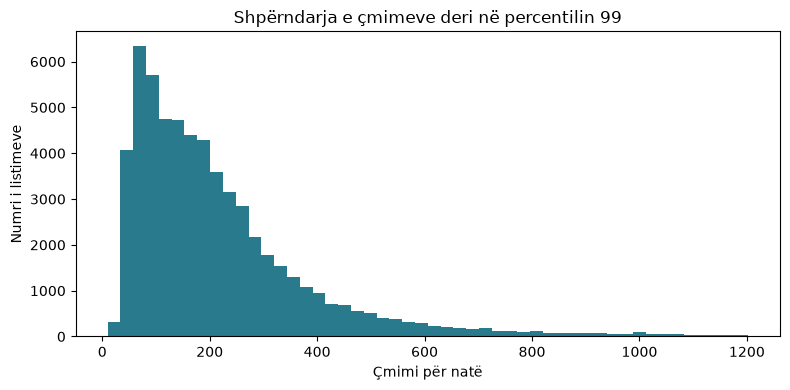

In [8]:
price_p99 = df["price"].quantile(0.99)
df["price_above_p99"] = df["price"].gt(price_p99)
print(f"P99: {price_p99:.2f}; listime mbi kufi: {int(df['price_above_p99'].sum()):,}")
ax = df.loc[~df["price_above_p99"], "price"].plot.hist(bins=50, figsize=(8, 4), color="#287a8c")
ax.set(xlabel="Çmimi për natë", ylabel="Numri i listimeve", title="Shpërndarja e çmimeve deri në percentilin 99")
plt.tight_layout()
plt.show()
record("Shënimi i çmimeve mbi P99")

### Anomali në kolona të tjera

Këto kolona kanë vlera të pazakonta që nuk janë gabime çmimi, prandaj këtu **nuk fshijmë rreshta**. Është e njëjta politikë si për çmimin: heqim vetëm atë që është gabim i dukshëm dhe shënojmë atë që mund të jetë e vërtetë.

- **`maximum_nights`** (dhe kolonat e tjera të netëve maksimale) ka vlera si 2,147,483,647, kufiri i një numri të plotë 32-bit. Ajo nuk është një numër i vërtetë netësh, por një shenjë "pa kufi". Kufizojmë vlerat në 1,125, që është vlera maksimale e zakonshme dhe percentili 99 i dataset-it. Listimi mbetet, hiqet vetëm vlera absurde.
- **`bedrooms` > `accommodates`** (p.sh. 2 dhoma gjumi për 1 mysafir) është e pazakontë, por jo e pamundur. Tabela më poshtë tregon se pothuajse të gjitha janë dhoma private, ndaj ka gjasa që hosti të ketë shënuar dhomat e gjithë shtëpisë. Vlerën nuk e ndryshojmë; e shënojmë te `bedrooms_above_accommodates`, që analiza ta përjashtojë ose ta shqyrtojë.
- **`bedrooms` = 0** nuk është gabim: shumica janë shtëpi të plota, pra studio. Nuk ndryshohet asgjë.
- **`host_listings_count`** arrin 5,777, ndërsa `calculated_host_listings_count` (listimet e host-it në këtë dataset) arrin 501. Vlera e raportuar nga Airbnb nuk është e qëndrueshme me dataset-in, por nuk është gabim çmimi: rreshtat mbeten dhe kolona nuk përdoret për analizë. Notebook-u 03 përdor `calculated_host_listings_count`.
- **`price_quote_*`** nuk janë veti të pavarura, por të nxjerra nga çmimi: `price_quote_price_per_night` është kopje e saktë e `price` (shih rezultatin më poshtë), `price_quote_total_price` është çmimi total i një qëndrimi shembull prej një ose më shumë netësh, dhe `price_quote_raw` e përmban çmimin si JSON. I mbajmë te tabela e plotë, por nuk futen te 18 kolonat e analizës, dhe duhen përjashtuar te zgjedhja e vetive (notebook-u 04), përndryshe një model do ta shihte vetë çmimin që duhet të parashikojë.
- **`scrape_id`** nuk është anomali, por konstante: ka të njëjtën vlerë në çdo rresht dhe hiqet te hapi 1.

In [9]:
MAX_NIGHTS_CAP = 1125
night_columns = [col for col in ["maximum_nights", "minimum_maximum_nights", "maximum_maximum_nights", "maximum_nights_avg_ntm"] if col in df]
largest_nights = df[night_columns].max().max()
capped = (df[night_columns] > MAX_NIGHTS_CAP).sum()
df[night_columns] = df[night_columns].clip(upper=MAX_NIGHTS_CAP)
display(capped.to_frame(f"vlera mbi {MAX_NIGHTS_CAP:,} të kufizuara"))
print(f"Vlera më e madhe e netëve maksimale: {largest_nights:,.0f} para kufizimit, {df[night_columns].max().max():,.0f} pas tij")

df["bedrooms_above_accommodates"] = (df["bedrooms"] > df["accommodates"]).astype(bool)
flagged = df[df["bedrooms_above_accommodates"]]
print(f"bedrooms > accommodates: {len(flagged):,} listime ({len(flagged) / len(df):.1%}), të shënuara te bedrooms_above_accommodates")
display(flagged["room_type"].value_counts().to_frame("listime të shënuara"))

studios = df["bedrooms"].eq(0)
print(f"bedrooms = 0: {int(studios.sum()):,} listime, nga të cilat {int((studios & df['room_type'].eq('Entire home/apt')).sum()):,} shtëpi të plota (studio); nuk ndryshohen")
print(f"host_listings_count: maksimumi {int(df['host_listings_count'].max()):,}; calculated_host_listings_count: maksimumi {int(df['calculated_host_listings_count'].max()):,}; nuk ndryshohen")

quote_per_night = pd.to_numeric(df["price_quote_price_per_night"].astype("string").str.replace(r"[$,]", "", regex=True), errors="coerce")
quote_known = quote_per_night.notna()
print(f"price_quote_price_per_night = price te {quote_per_night[quote_known].eq(df.loc[quote_known, 'price']).mean():.1%} e {int(quote_known.sum()):,} vlerave jo-boshe; kolonat price_quote_* mbahen, por duhen përjashtuar nga vetitë e modelit")
record("Anomali: maximum_nights i kufizuar, bedrooms > accommodates i shënuar")

,"vlera mbi 1,125 të kufizuara"
maximum_nights,23
minimum_maximum_nights,16
maximum_maximum_nights,23
maximum_nights_avg_ntm,22


Vlera më e madhe e netëve maksimale: 2,147,483,647 para kufizimit, 1,125 pas tij
bedrooms > accommodates: 375 listime (0.6%), të shënuara te bedrooms_above_accommodates


,listime të shënuara
room_type,
Private room,348
Entire home/apt,25
Hotel room,1
Shared room,1


bedrooms = 0: 2,121 listime, nga të cilat 1,728 shtëpi të plota (studio); nuk ndryshohen
host_listings_count: maksimumi 5,777; calculated_host_listings_count: maksimumi 501; nuk ndryshohen
price_quote_price_per_night = price te 100.0% e 59,702 vlerave jo-boshe; kolonat price_quote_* mbahen, por duhen përjashtuar nga vetitë e modelit


## 4. Krijimi i vetive, binarizimi dhe diskretizimi

`has_reviews` dhe `is_superhost` janë veti binare. `price_band` e ndan çmimin në tri grupe sipas tercileve të këtij dataset-i. Nëse çmimi përdoret si variabël që parashikohet, **mos përdorni `price_band` si hyrje të modelit**: ajo është krijuar nga vetë çmimi. `amenity_count` numëron lehtësitë e listuara te `amenities`; ato lexohen si listë JSON (`json.loads`), jo duke numëruar thonjëzat, sepse emri i një lehtësie mund të përmbajë vetë thonjëza.

In [10]:
df["has_reviews"] = df["number_of_reviews"].gt(0)
df["is_superhost"] = df["host_is_superhost"].astype("boolean")
df["price_band"] = pd.qcut(df["price"], q=3, labels=["i ulët", "mesatar", "i lartë"], duplicates="drop")
df["amenity_count"] = df["amenities"].fillna("[]").map(lambda text: len(json.loads(text)))
record("Vetitë e reja dhe kategoritë")
display(df[["price", "price_band", "has_reviews", "is_superhost", "amenity_count"]].head())

,price,price_band,has_reviews,is_superhost,amenity_count
0,267.5,i lartë,True,False,43
1,127.0,mesatar,True,True,44
2,137.5,mesatar,True,False,25
3,228.0,mesatar,True,False,68
5,290.0,i lartë,True,False,47


## 5. Zgjedhja e vetive dhe reduktimi i dimensionit

Për analizën e çmimit ruajmë një nënbashkësi të kuptueshme kolonash. ID-të, URL-të dhe teksti i gjatë nuk nevojiten si veti numerike në këtë fazë. `id` ruhet vetëm për gjurmim. Numri i kolonave bie edhe nga heqja e kolonave krejt bosh. PCA nuk përdoret këtu, sepse do të vështirësonte interpretimin e lagjes, llojit të dhomës dhe kapacitetit.

Këto 18 kolona janë një tabelë analize, jo bashkësia përfundimtare e vetive të një modeli: zgjedhja e justifikuar me numra (korrelacione, variancë) bëhet te notebook-u 04.

In [11]:
selected = ["id", "neighbourhood_cleansed", "room_type", "property_type", "accommodates", "bathrooms", "bedrooms", "beds", "price", "price_above_p99", "availability_365", "number_of_reviews", "reviews_per_month", "review_scores_rating", "has_reviews", "is_superhost", "amenity_count", "price_band"]
analysis = df[selected].copy()
print(f"Kolonat: {raw.shape[1]} fillestare → {df.shape[1]} pas pastrimit/krijimit → {analysis.shape[1]} për analizë")
display(analysis.head())

Kolonat: 90 fillestare → 87 pas pastrimit/krijimit → 18 për analizë


,id,neighbourhood_cleansed,room_type,property_type,accommodates,bathrooms,bedrooms,beds,price,price_above_p99,availability_365,number_of_reviews,reviews_per_month,review_scores_rating,has_reviews,is_superhost,amenity_count,price_band
0,11551,Lambeth,Entire home/apt,Entire rental unit,5,1.0,1,3,267.5,False,349,197,0.98,4.55,True,False,43,i lartë
1,13913,Islington,Private room,Private room in rental unit,1,1.0,1,1,127.0,False,350,57,0.29,4.86,True,True,44,mesatar
2,15400,Kensington and Chelsea,Entire home/apt,Entire rental unit,2,1.0,1,1,137.5,False,159,98,0.48,4.81,True,False,25,mesatar
3,24328,Wandsworth,Entire home/apt,Entire townhouse,2,1.5,1,1,228.0,False,272,97,0.50,4.90,True,False,68,mesatar
5,36299,Richmond upon Thames,Entire home/apt,Entire townhouse,5,1.5,3,3,290.0,False,350,117,0.60,4.80,True,False,47,i lartë


## 6. Agregimi

Për raportimin deskriptiv llogarisim medianën e çmimit sipas llojit të dhomës dhe lagjes. Standardizimi, kodimi 0/1 dhe transformimet e tjera (p.sh. logaritmi i çmimit) nuk bëhen këtu: janë pjesë e notebook-eve 03 dhe 04, ku kanë një vend të vetëm.

,count,median
room_type,,
Shared room,164,35.71
Private room,19067,80.0
Hotel room,134,187.5
Entire home/apt,40481,226.67


,count,median
neighbourhood_cleansed,,
Westminster,7942,281.55
Kensington and Chelsea,4648,272.5
Camden,4291,207.5
Tower Hamlets,3875,161.5
Southwark,3029,157.67
Lambeth,2829,153.0
Hackney,2826,164.38
Wandsworth,2691,185.09
Hammersmith and Fulham,2680,184.0


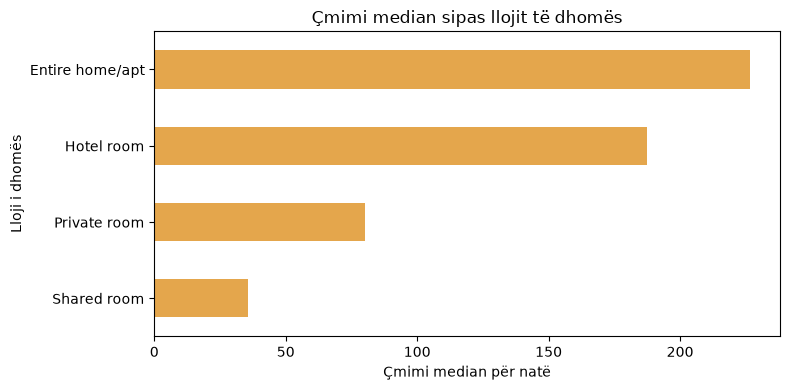

In [12]:
by_room = analysis.groupby("room_type")["price"].agg(["count", "median"]).sort_values("median")
by_area = analysis.groupby("neighbourhood_cleansed")["price"].agg(["count", "median"]).sort_values("count", ascending=False)
display(by_room.round(2))
display(by_area.head(10).round(2))
ax = by_room["median"].plot.barh(figsize=(8, 4), color="#e4a64c")
ax.set(xlabel="Çmimi median për natë", ylabel="Lloji i dhomës", title="Çmimi median sipas llojit të dhomës")
plt.tight_layout()
plt.show()

## 7. Kontrolli para/pas dhe ruajtja

Raporti tregon çfarë ndryshoi në secilin hap, çfarë ndodhi me çdo rresht të dataset-it, çfarë ndodhi me mungesat e secilës kolonë dhe nëse ka mbetur ndonjë problem. Dataset-i final ruhet pa ndryshuar skedarin origjinal.

### 7.1 Hapat e pastrimit

In [13]:
display(pd.DataFrame(log))

,hapi,rreshta,kolona,qeliza boshe
0,Fillimi,91954,90,1933263
1,"Kolona boshe, konstante, ID, tipe",91954,75,645907
2,Integrimi: numri dhe datat e komenteve nga rev...,91954,78,687295
3,Integrimi: disponueshmëria sipas ditës nga cal...,91954,80,687295
4,Heqja e çmimit të munguar/jo pozitiv,59905,81,313609
5,Plotësimi i zgjedhur i mungesave,59905,81,239917
6,Heqja e çmimeve ekstreme (P99.9 sipas llojit t...,59846,81,239479
7,Shënimi i çmimeve mbi P99,59846,82,239479
8,"Anomali: maximum_nights i kufizuar, bedrooms >...",59846,83,239479
9,Vetitë e reja dhe kategoritë,59846,87,239479


### 7.2 Çfarë ndodhi me rreshtat

Çdo rresht është ose i mbajtur ose i hequr për një arsye. Boshti është logaritmik, sepse ka shumë më tepër rreshta të mbajtur se të hequr.

,rreshta
të mbajtur,59846
hequr: ID e dyfishuar,0
hequr: pa çmim,32049
hequr: çmim <= 0,0
hequr: çmim ekstrem,59


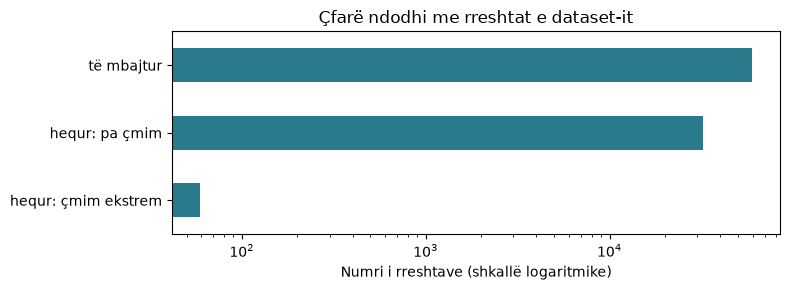

In [14]:
fate = pd.Series({"të mbajtur": len(df), **{f"hequr: {reason}": count for reason, count in removed.items()}})
assert fate.sum() == len(raw), "Çdo rresht duhet të jetë i mbajtur ose i hequr"
display(fate.to_frame("rreshta"))
ax = fate[fate.gt(0)].sort_values().plot.barh(figsize=(8, 3), color="#287a8c")
ax.set(xscale="log", xlabel="Numri i rreshtave (shkallë logaritmike)", title="Çfarë ndodhi me rreshtat e dataset-it")
plt.tight_layout()
plt.show()

### 7.3 Strategjia për mungesat, kolonë për kolonë

Tabela ka një rresht për çdo kolonë që kishte mungesa në dataset-in origjinal, me vendimin dhe arsyen. `veprimi` është njëri nga:
- `kolonë e hequr`: kolona ishte krejt bosh dhe u hoq;
- `plotësuar`: mungesat u plotësuan me një rregull të shpjeguar;
- `rreshta të hequr`: mungesat ishin vetëm te rreshtat e hequr, ndaj te rreshtat e mbajtur nuk mbeti asnjë;
- `lënë bosh`: mungesat u lanë me qëllim.

`mungesa para` dhe `% para` numërojnë të gjitha rreshtat fillestarë; `mungesa pas` dhe `% pas` numërojnë vetëm rreshtat e mbajtur. Kolonat që nuk kishin asnjë mungesë nuk kanë nevojë për vendim dhe mbeten siç janë.

39 nga 93 kolona nuk kishin asnjë mungesë; tabela më poshtë ka 54 kolonat me mungesa.


,kolona
veprimi,
kolonë e hequr,14
plotësuar,6
rreshta të hequr,10
lënë bosh,24


,mungesa para,% para,mungesa pas,% pas,veprimi,arsyeja
neighborhood_overview,91954,100.0,—,—,kolonë e hequr,"kolona është 100% bosh, pa asnjë informacion"
host_since,91954,100.0,—,—,kolonë e hequr,"kolona është 100% bosh, pa asnjë informacion"
host_response_time,91954,100.0,—,—,kolonë e hequr,"kolona është 100% bosh, pa asnjë informacion"
host_response_rate,91954,100.0,—,—,kolonë e hequr,"kolona është 100% bosh, pa asnjë informacion"
host_acceptance_rate,91954,100.0,—,—,kolonë e hequr,"kolona është 100% bosh, pa asnjë informacion"
host_thumbnail_url,91954,100.0,—,—,kolonë e hequr,"kolona është 100% bosh, pa asnjë informacion"
host_neighbourhood,91954,100.0,—,—,kolonë e hequr,"kolona është 100% bosh, pa asnjë informacion"
host_total_listings_count,91954,100.0,—,—,kolonë e hequr,"kolona është 100% bosh, pa asnjë informacion"
host_verifications,91954,100.0,—,—,kolonë e hequr,"kolona është 100% bosh, pa asnjë informacion"
neighbourhood,91954,100.0,—,—,kolonë e hequr,"kolona është 100% bosh, pa asnjë informacion"


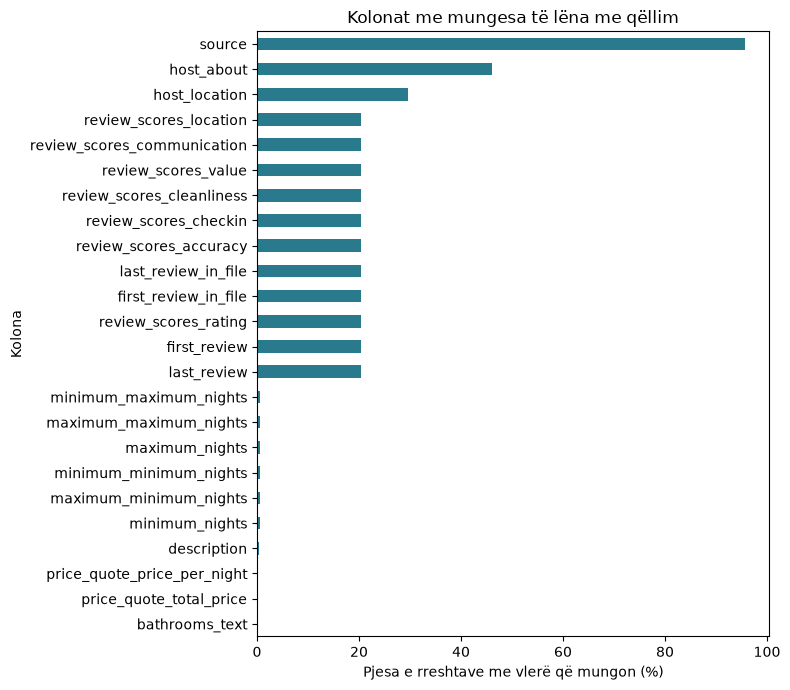

In [15]:
raw_ext = raw.join(joined_snapshot)  # kolonat origjinale plus ato që krijoi bashkimi, para çdo plotësimi

def missing_action(col):
    if col not in df:
        return "kolonë e hequr"
    before = raw_ext.loc[df.index, col].isna().sum()
    after = df[col].isna().sum()
    if after < before:
        return "plotësuar"
    return "rreshta të hequr" if before == 0 else "lënë bosh"

median_fill = "numër; plotësuar me medianën e listimeve me të njëjtin accommodates"
no_reviews = "listimi pa komente nuk ka vlerësim; plotësimi do t'i jepte një notë që nuk e ka marrë kurrë"
no_review_date = "listimi pa komente nuk ka datë; plotësimi do t'i jepte një datë që nuk ka ndodhur"
reasons = {
    "bathrooms": "rindërtuar nga bathrooms_text ('No bathroom' = 0, 'Half-bath' = 0.5); pjesa e mbetur me medianën sipas accommodates",
    "bedrooms": median_fill,
    "beds": median_fill,
    "has_availability": "nxjerrë nga availability_365: True kur listimi ka ditë të lira",
    "reviews_per_month": "listimi pa komente ka 0 komente në muaj; plotësuar me 0 vetëm kur number_of_reviews = 0",
    "price": "variabla që analizojmë; plotësimi do të sajonte çmime, prandaj listimet pa çmim u hoqën",
    "source": "vlera e vetme është 'previous scrape'; boshllëku do të thotë mbledhje e zakonshme, është etiketë",
    "description": "tekst i lirë; nuk plotësohet me tekst të sajuar",
    "host_location": "tekst i lirë që hosti nuk e ka dhënë; analiza e çmimit nuk e përdor",
    "host_about": "tekst i lirë; një biografi e sajuar do të ishte e gabuar",
    "bathrooms_text": "boshllëk i vogël; bathrooms plotësohet me medianë aty ku mungon",
    "price_quote_total_price": "çmimi i një qëndrimi shembull, i nxjerrë nga price; boshllëk i vogël; përjashtohet nga vetitë e modelit",
    "price_quote_price_per_night": "kopje e saktë e price; boshllëk i vogël; përjashtohet nga vetitë e modelit",
    "first_review": no_review_date,
    "last_review": no_review_date,
    "reviews_in_file": "krijuar nga bashkimi me reviews.csv; listimi pa komente në skedar ka 0 komente, jo vlerë të panjohur, prandaj plotësuar me 0",
    "first_review_in_file": "krijuar nga bashkimi me reviews.csv; " + no_review_date,
    "last_review_in_file": "krijuar nga bashkimi me reviews.csv; " + no_review_date,
}
reasons.update({col: no_reviews for col in raw.columns if col.startswith("review_scores_")})
reasons.update({col: "boshllëk i vogël; analiza e çmimit nuk e kërkon dhe një supozim për netët do të ishte i sajuar"
                for col in raw.columns if "nights" in col})

def reason_for(col, action):
    if action == "kolonë e hequr":
        return "kolona është 100% bosh, pa asnjë informacion"
    if action == "rreshta të hequr":
        return reasons.get(col, "mungesat ishin vetëm te rreshtat e hequr (pa çmim), ndaj nuk ka çfarë të plotësohet")
    return reasons[col]  # një kolonë e re me mungesa kërkon një vendim të shkruar këtu

missing_before = raw_ext.isna().sum()
missing_before = missing_before[missing_before.gt(0)]
missing = pd.DataFrame({
    "mungesa para": missing_before,
    "% para": (missing_before / len(raw) * 100).round(1),
    "mungesa pas": df.isna().sum().reindex(missing_before.index).astype("Int64"),
})
missing["% pas"] = (missing["mungesa pas"] / len(df) * 100).astype(float).round(1)
missing["veprimi"] = [missing_action(col) for col in missing.index]
missing["arsyeja"] = [reason_for(col, action) for col, action in zip(missing.index, missing["veprimi"])]
order = {"kolonë e hequr": 0, "plotësuar": 1, "rreshta të hequr": 2, "lënë bosh": 3}
missing = missing.sort_values("veprimi", key=lambda s: s.map(order), kind="stable")

print(f"{raw_ext.shape[1] - len(missing)} nga {raw_ext.shape[1]} kolona nuk kishin asnjë mungesë; tabela më poshtë ka {len(missing)} kolonat me mungesa.")
display(missing.groupby("veprimi").size().reindex(list(order)).to_frame("kolona"))
with pd.option_context("display.max_colwidth", None, "display.max_rows", None):
    display(missing.astype(object).where(missing.notna(), "—"))

kept = missing[missing["veprimi"].eq("lënë bosh")]
ax = (kept["mungesa pas"] / len(df) * 100).sort_values().plot.barh(figsize=(8, 7), color="#287a8c")
ax.set(xlabel="Pjesa e rreshtave me vlerë që mungon (%)", ylabel="Kolona", title="Kolonat me mungesa të lëna me qëllim")
plt.tight_layout()
plt.show()

### 7.4 Kontrollet përfundimtare

Të gjitha vlerat më poshtë duhet të jenë 0. Nëse ndonjëra nuk është, pastrimi ka lënë një problem dhe qeliza ndalon.

In [16]:
no_bathroom = df["bathrooms_text"].str.contains(r"^no bath", case=False, na=False)
checks = pd.Series({
    "çmim që mungon": int(df["price"].isna().sum()),
    "çmim <= 0": int(df["price"].le(0).sum()),
    "ID të dyfishuara": int(df["id"].duplicated().sum()),
    "bathrooms, bedrooms ose beds që mungojnë": int(df[["bathrooms", "bedrooms", "beds"]].isna().sum().sum()),
    "reviews_per_month që mungon": int(df["reviews_per_month"].isna().sum()),
    "has_availability që mungon": int(df["has_availability"].isna().sum()),
    "netë maksimale mbi kufirin": int(df[night_columns].gt(MAX_NIGHTS_CAP).sum().sum()),
    "'No bathroom' me bathrooms jo 0": int(df.loc[no_bathroom, "bathrooms"].ne(0).sum()),
})
display(checks.to_frame("numri"))
assert checks.eq(0).all(), "Pas pastrimit kanë mbetur probleme"

,numri
çmim që mungon,0
çmim <= 0,0
ID të dyfishuara,0
"bathrooms, bedrooms ose beds që mungojnë",0
reviews_per_month që mungon,0
has_availability që mungon,0
netë maksimale mbi kufirin,0
'No bathroom' me bathrooms jo 0,0


### 7.5 Ruajtja

Ruajmë dy skedarë në `dataset/`: `listings_clean_full.csv` (tabela e plotë, hyrja e notebook-ut 03) dhe `listings_preprocessed.csv` (18 kolonat e analizës).

In [17]:
print(f"Rezultati për analizë: {len(analysis):,} rreshta × {analysis.shape[1]} kolona")
print(f"Vlerësime të mungura të ruajtura: {analysis['review_scores_rating'].isna().sum():,}")
output = ROOT / "dataset" / "listings_preprocessed.csv"
full_output = ROOT / "dataset" / "listings_clean_full.csv"
output.parent.mkdir(parents=True, exist_ok=True)
analysis.to_csv(output, index=False)
df.to_csv(full_output, index=False)
print(f"U ruajt: {output.relative_to(ROOT)} ({analysis.shape[1]} kolona)")
print(f"U ruajt: {full_output.relative_to(ROOT)} ({df.shape[1]} kolona)")

Rezultati për analizë: 59,846 rreshta × 18 kolona
Vlerësime të mungura të ruajtura: 12,226


U ruajt: dataset/listings_preprocessed.csv (18 kolona)
U ruajt: dataset/listings_clean_full.csv (87 kolona)
